# Google Play Store Apps - EDA

**Question:** How do app category, ratings, installs, and user reviews vary?

**Dataset:** [Google Play Store Apps on Kaggle](https://www.kaggle.com/datasets/lava18/google-play-store-apps)  
Files: `googleplaystore.csv` and `googleplaystore_user_reviews.csv` (both CSV files are in this folder), plus `license.txt`. The app and review tables are related by app name. Licence details are in `archive/license.txt`; check them before reuse.

Data analysis uses Pandas and plots use Seaborn. Both CSV files are loaded directly from this folder.

## 1. Load and look at the data
We keep the original tables as raw data and make separate working copies.

In [1]:
import pandas as pd
import seaborn as sns

Imports Pandas for table operations and Seaborn for charts.

In [2]:
apps_raw = pd.read_csv("googleplaystore.csv")
reviews_raw = pd.read_csv("googleplaystore_user_reviews.csv")

Loads the app and user-review CSV files into separate raw tables.

In [3]:
apps_raw.shape, reviews_raw.shape

((10841, 13), (64295, 5))

Shows how many rows and columns are in each raw table.

In [4]:
apps_raw.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


Displays the first few app records to preview the data.

In [5]:
apps_raw.dtypes

App                object
Category           object
Rating            float64
Reviews            object
Size               object
Installs           object
Type               object
Price              object
Content Rating     object
Genres             object
Last Updated       object
Current Ver        object
Android Ver        object
dtype: object

Shows the data type of each app column.

In [6]:
apps_raw.isna().sum()

App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

Counts missing values in each original app column.

The app file contains one malformed row: its values are shifted into the wrong columns. We remove that row only from the working copy. Missing values are left missing instead of guessed.

In [7]:
apps = apps_raw.copy()
reviews = reviews_raw.copy()
apps = apps[apps["App"] != "Life Made WI-Fi Touchscreen Photo Frame"]

Creates working copies and removes the known malformed app row from the working data.

In [8]:
apps.shape, apps["App"].duplicated().sum()

((10840, 13), np.int64(1181))

Checks the cleaned row count and counts repeated app names.

Some app names repeat in the source data. We count them but do not drop them automatically because repeated rows may need investigation.

## 2. Make useful columns
Convert text columns to numbers so they can be used in calculations.

In [9]:
apps["Rating"] = pd.to_numeric(apps["Rating"], errors="coerce")
apps["Reviews_num"] = pd.to_numeric(apps["Reviews"], errors="coerce")

Converts rating and review counts to numeric values for analysis.

In [10]:
apps["Installs_num"] = pd.to_numeric(apps["Installs"].str.replace("+", "", regex=False).str.replace(",", "", regex=False), errors="coerce")

Removes plus signs and commas, then converts install counts to numbers.

In [11]:
apps["Price_num"] = pd.to_numeric(apps["Price"].str.replace("$", "", regex=False), errors="coerce")

Removes the dollar sign and converts app prices to numbers.

In [12]:
apps["Size_mb"] = pd.to_numeric(apps["Size"].str.replace("M", "", regex=False), errors="coerce")

Converts app sizes recorded in megabytes into numeric values.

`Size_mb` works for sizes written in MB. Values marked ?Varies with device? and sizes written in KB remain missing in this simple conversion; we do not mix units.

In [13]:
apps["Last_Updated"] = pd.to_datetime(apps["Last Updated"], errors="coerce")
apps["Update_month"] = apps["Last_Updated"].dt.month

Converts update dates and extracts the month as a new feature.

In [14]:
apps["Days_since_update"] = (pd.Timestamp.today().normalize() - apps["Last_Updated"]).dt.days

Converts update dates and extracts the month as a new feature.

In [15]:
apps["Is_paid"] = apps["Type"] == "Paid"

Creates a True/False feature to identify paid apps.

In [16]:
apps["Price_per_review"] = apps["Price_num"] / apps["Reviews_num"].replace(0, float("nan"))

Removes the dollar sign and converts app prices to numbers.

We created several features: `Installs_num` (clean numeric install count), `Price_num` (price as a number), `Size_mb` (size in MB), `Update_month` (month of last update), `Days_since_update` (update recency), `Is_paid` (True/False), and `Price_per_review` (price divided by review count). Missing or zero denominators can produce missing results and are not filled with invented values.

## 3. Group and summarize apps
`groupby()` makes groups; `agg()` gives a summary for each group. `transform()` adds a group result back to every matching row.

In [17]:
category_summary = apps.groupby("Category")["Rating"].agg(["count", "mean", "median", "min", "max"])
category_summary.head()

,count,mean,median,min,max
Category,,,,,
ART_AND_DESIGN,62,4.358065,4.4,3.2,5.0
AUTO_AND_VEHICLES,73,4.190411,4.3,2.1,4.9
BEAUTY,42,4.278571,4.3,3.1,4.9
BOOKS_AND_REFERENCE,178,4.346067,4.5,2.7,5.0
BUSINESS,303,4.121452,4.3,1.0,5.0


Groups apps by category and calculates rating count, mean, median, minimum, and maximum.

In [18]:
apps["Category_average_rating"] = apps.groupby("Category")["Rating"].transform("mean")
apps[["Category", "App", "Rating", "Category_average_rating"]].head()

,Category,App,Rating,Category_average_rating
0,ART_AND_DESIGN,Photo Editor & Candy Camera & Grid & ScrapBook,4.1,4.358065
1,ART_AND_DESIGN,Coloring book moana,3.9,4.358065
2,ART_AND_DESIGN,"U Launcher Lite – FREE Live Cool Themes, Hide ...",4.7,4.358065
3,ART_AND_DESIGN,Sketch - Draw & Paint,4.5,4.358065
4,ART_AND_DESIGN,Pixel Draw - Number Art Coloring Book,4.3,4.358065


Adds each app?s category average rating alongside its own rating.

The summary table has one row per category. The transformed average stays aligned with each app row, so it can be compared with the app's own rating.

[Text(0.5, 1.0, 'Average rating for 10 app categories'),
 Text(0.5, 0, 'Average rating'),
 Text(0, 0.5, 'Category')]

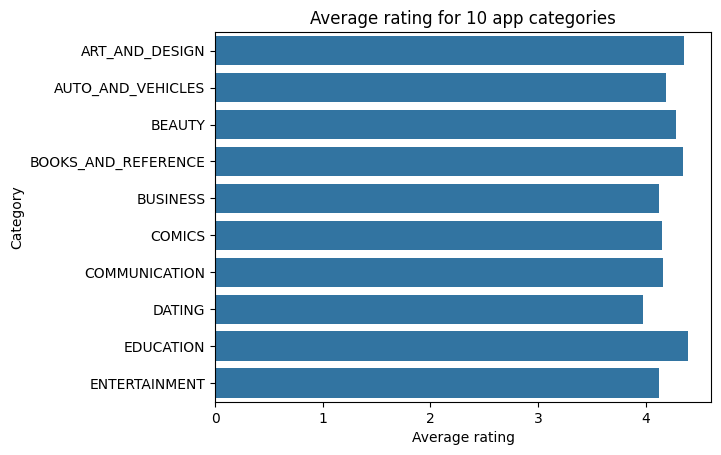

In [19]:
sns.barplot(data=category_summary.reset_index().head(10), x="mean", y="Category").set(
    title="Average rating for 10 app categories", xlabel="Average rating", ylabel="Category")

Plots average ratings for the first ten app categories.

**Observations:** This chart compares category average ratings. The highest bars have higher averages among categories shown. Check the count column too, because averages based on fewer apps may vary more.

## 4. Pivot table and crosstab
These tables compare category and app type in two ways.

In [20]:
apps.pivot_table(index="Category", columns="Type", values="Rating", aggfunc="mean").head()

Type,Free,Paid
Category,,
ART_AND_DESIGN,4.338983,4.733333
AUTO_AND_VEHICLES,4.184722,4.600000
BEAUTY,4.278571,NaN
BOOKS_AND_REFERENCE,4.349412,4.275000
BUSINESS,4.118493,4.200000


Shows mean ratings for each app category and app type.

The pivot table shows average app rating for each category and app type.

In [21]:
pd.crosstab(apps["Category"], apps["Type"]).head()

Type,Free,Paid
Category,,
ART_AND_DESIGN,62,3
AUTO_AND_VEHICLES,82,3
BEAUTY,53,0
BOOKS_AND_REFERENCE,203,28
BUSINESS,446,14


Counts free and paid apps in each category.

The crosstab counts the number of free and paid apps in each category.

## 5. Change table shape
Wide tables have measurements in columns. Long tables put the measurement name and value into rows.

In [22]:
small_apps = apps[["App", "Rating", "Installs_num"]].head()

Selects a small sample of app names, ratings, and install counts for reshaping.

In [23]:
long_apps = small_apps.melt(id_vars="App", var_name="Measure", value_name="Value")
long_apps

,App,Measure,Value
0,Photo Editor & Candy Camera & Grid & ScrapBook,Rating,4.1
1,Coloring book moana,Rating,3.9
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",Rating,4.7
3,Sketch - Draw & Paint,Rating,4.5
4,Pixel Draw - Number Art Coloring Book,Rating,4.3
5,Photo Editor & Candy Camera & Grid & ScrapBook,Installs_num,10000.0
6,Coloring book moana,Installs_num,500000.0
7,"U Launcher Lite – FREE Live Cool Themes, Hide ...",Installs_num,5000000.0
8,Sketch - Draw & Paint,Installs_num,50000000.0
9,Pixel Draw - Number Art Coloring Book,Installs_num,100000.0


Changes selected columns into long format, with measure names and values in rows.

In [24]:
wide_apps = long_apps.pivot(index="App", columns="Measure", values="Value")
wide_apps

Measure,Installs_num,Rating
App,,
Coloring book moana,500000.0,3.9
Photo Editor & Candy Camera & Grid & ScrapBook,10000.0,4.1
Pixel Draw - Number Art Coloring Book,100000.0,4.3
Sketch - Draw & Paint,50000000.0,4.5
"U Launcher Lite – FREE Live Cool Themes, Hide Apps",5000000.0,4.7


Pivots the long sample back into a wide table.

`melt()` changed columns into rows; `pivot()` changed those rows back into columns. This helps prepare data for different tables and plots.

In [25]:
category_type = apps.groupby(["Category", "Type"])["Rating"].mean().reset_index()
category_wide = category_type.pivot(index="Category", columns="Type", values="Rating")

Calculates average rating for each category and app type, then arranges it as a pivot table.

In [26]:
category_wide.head()

Type,Free,Paid
Category,,
ART_AND_DESIGN,4.338983,4.733333
AUTO_AND_VEHICLES,4.184722,4.600000
BEAUTY,4.278571,NaN
BOOKS_AND_REFERENCE,4.349412,4.275000
BUSINESS,4.118493,4.200000


Displays the first category-by-type rows of the pivot table.

In [27]:
category_wide.stack().head()

Category           Type
ART_AND_DESIGN     Free    4.338983
                   Paid    4.733333
AUTO_AND_VEHICLES  Free    4.184722
                   Paid    4.600000
BEAUTY             Free    4.278571
dtype: float64

Moves app-type column labels into rows.

In [28]:
category_wide.stack().unstack().head()

Type,Free,Paid
Category,,
ART_AND_DESIGN,4.338983,4.733333
AUTO_AND_VEHICLES,4.184722,4.600000
BEAUTY,4.278571,NaN
BOOKS_AND_REFERENCE,4.349412,4.275000
BUSINESS,4.118493,4.200000


Moves app-type column labels into rows.

`stack()` moves column labels into rows; `unstack()` moves them back into columns. Here the category/type averages have one value for each combination.

## 6. Combine apps and reviews
The app name appears in both files. Reviews have many rows per app, so first make one review summary per app to avoid repeating app rows.

In [29]:
apps["App_key"] = apps["App"].str.lower().str.strip()
reviews["App_key"] = reviews["App"].str.lower().str.strip()

Makes app names lowercase and removes extra spaces so the two tables can be matched.

In [30]:
review_summary = reviews.groupby("App_key")["Sentiment_Polarity"].mean().reset_index()
review_summary.head()

,App_key,Sentiment_Polarity
0,10 best foods for you,0.470733
1,104 找工作 - 找工作 找打工 找兼職 履歷健檢 履歷診療室,0.392405
2,11st,0.181294
3,1800 contacts - lens store,0.318145
4,1line – one line with one touch,0.196290


Calculates one average review sentiment value for each app name.

The app table can contain repeated app names. The review summary has one row per normalized app name. We keep the repeated app rows and merge the summary onto them.

In [31]:
apps_with_reviews = apps.merge(review_summary, on="App_key", how="left")
apps.shape, apps_with_reviews.shape

((10840, 24), (10840, 25))

Left-merges review sentiment onto apps and compares row counts before and after.

In [32]:
apps_with_reviews["Sentiment_Polarity"].isna().sum()

np.int64(9608)

Counts app rows with no matching review sentiment.

The left merge keeps all app rows. Missing sentiment after the merge means no review summary matched that app name. We compare row counts to check that the merge did not multiply app rows.

In [33]:
app_categories = apps[["App_key", "Category"]].drop_duplicates().set_index("App_key")
review_scores = review_summary.set_index("App_key")
app_categories.join(review_scores).head()

,Category,Sentiment_Polarity
App_key,,
photo editor & candy camera & grid & scrapbook,ART_AND_DESIGN,NaN
coloring book moana,ART_AND_DESIGN,0.152652
"u launcher lite – free live cool themes, hide apps",ART_AND_DESIGN,NaN
sketch - draw & paint,ART_AND_DESIGN,NaN
pixel draw - number art coloring book,ART_AND_DESIGN,NaN


Joins app categories and review summaries using the app name as the index.

`join()` matches rows by their index. Both small tables use the normalized app name as the index.

In [34]:
free_apps = apps[apps["Type"] == "Free"][["App", "Category", "Type"]]
paid_apps = apps[apps["Type"] == "Paid"][["App", "Category", "Type"]]
pd.concat([free_apps, paid_apps]).head()

,App,Category,Type
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,Free
1,Coloring book moana,ART_AND_DESIGN,Free
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,Free
3,Sketch - Draw & Paint,ART_AND_DESIGN,Free
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,Free


Combines free and paid app rows vertically with concat.

`concat()` puts the free and paid app rows together. Rows with another or missing type are not included in this small demonstration.

In [35]:
apps.merge(review_summary, on="App_key", how="inner").shape

(1535, 25)

Counts rows retained by an inner merge, which keeps only matching app names.

In [36]:
apps.merge(review_summary, on="App_key", how="left").shape

(10840, 25)

Counts rows retained by a left merge, which keeps every app row.

In [37]:
apps.merge(review_summary, on="App_key", how="right").shape

(1589, 25)

Counts rows retained by a right merge, which keeps every review-summary row.

In [38]:
apps.merge(review_summary, on="App_key", how="outer").shape

(10894, 25)

Counts rows retained by an outer merge, which keeps keys from both tables.

Inner keeps matching names; left keeps all apps; right keeps all review summaries; outer keeps names from either table. The app name is not unique in the app table. Summarizing reviews first avoids one app row being repeated for each individual review.

## 7. Describe numerical columns
The standard deviation and variance below use Pandas sample calculations.

In [39]:
apps[["Rating", "Reviews_num"]].mean()

Rating              4.191757
Reviews_num    444152.896033
dtype: float64

Calculates the average app rating and review count.

In [40]:
apps[["Rating", "Reviews_num"]].median()

Rating            4.3
Reviews_num    2094.0
dtype: float64

Finds the middle rating and review-count values.

In [41]:
apps[["Rating", "Reviews_num"]].mode().head()

,Rating,Reviews_num
0,4.4,0


Displays the most frequent rating and review-count values.

In [42]:
apps[["Rating", "Reviews_num"]].std()

Rating         5.152189e-01
Reviews_num    2.927761e+06
dtype: float64

Measures rating and review-count spread using standard deviation.

In [43]:
apps[["Rating", "Reviews_num"]].var()

Rating         2.654505e-01
Reviews_num    8.571782e+12
dtype: float64

Measures rating and review-count spread using variance.

In [44]:
apps[["Rating", "Reviews_num"]].max() - apps[["Rating", "Reviews_num"]].min()

Rating                4.0
Reviews_num    78158306.0
dtype: float64

Calculates the range by subtracting each minimum from its maximum.

Mean is the average, median is the middle value, and mode is the most common value. Standard deviation describes spread in original units; variance is in squared units; range is maximum minus minimum. Rating mean is about 4.19 and median about 4.3, which suggests a longer lower tail. Review counts can have extreme high values, so their median is useful to compare with the mean.

In [45]:
apps["Rating"].quantile([0, .10, .25, .50, .75, .90, 1])

0.00    1.0
0.10    3.6
0.25    4.0
0.50    4.3
0.75    4.5
0.90    4.7
1.00    5.0
Name: Rating, dtype: float64

Displays selected rating percentiles, including the quartiles and median.

In [46]:
apps["Rating"].skew(), apps["Rating"].kurt()

(np.float64(-1.8496951283704521), np.float64(5.7869240668056))

Calculates rating skewness and excess kurtosis.

Quartiles split ordered data into four parts; the interquartile range is Q3 minus Q1 and describes the middle half. Rating skew is negative (longer lower tail). Pandas reports excess kurtosis, where zero is the normal reference. These summaries help show skew and unusual values.

## 8. Look at distributions
Use histograms to see the shape of the data. A real variable does not have to be normally distributed.

[Text(0.5, 1.0, 'App ratings'),
 Text(0.5, 0, 'Rating'),
 Text(0, 0.5, 'Number of apps')]

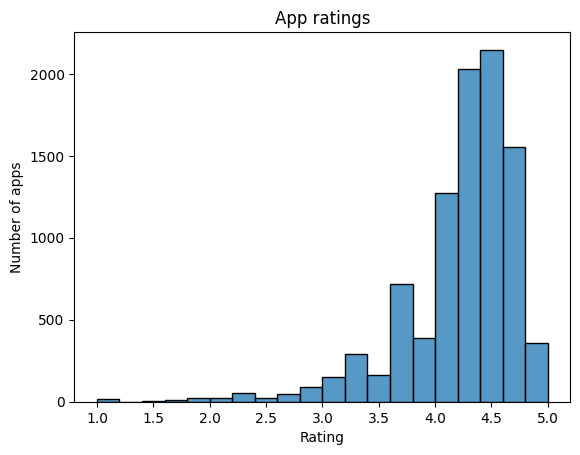

In [47]:
sns.histplot(data=apps, x="Rating", bins=20).set(
    title="App ratings", xlabel="Rating", ylabel="Number of apps")

Plots the distribution of app ratings as a histogram.

**Observations:** Most ratings are toward the high end. The lower tail is longer than the upper tail, matching the negative skew result.

[Text(0.5, 1.0, 'App installs on a log scale'),
 Text(0.5, 0, 'Installs'),
 Text(0, 0.5, 'Number of apps')]

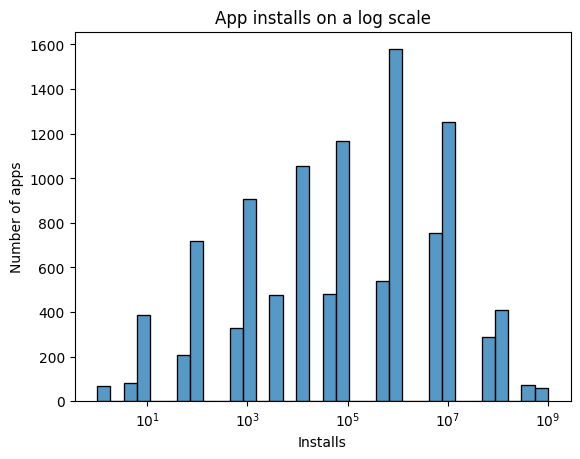

In [48]:
sns.histplot(data=apps, x="Installs_num", log_scale=True).set(
    title="App installs on a log scale", xlabel="Installs", ylabel="Number of apps")

Plots install counts on a log scale to show small and large values together.

**Observations:** Install counts vary widely and are right-skewed. The log scale makes both small and large install values easier to see.

## 9. Sampling and the Central Limit Theorem
A sample is a subset of app ratings. Repeating samples produces different sample means. A fixed seed makes the demonstration repeatable.

In [49]:
ratings = apps["Rating"].dropna()
sample_means = []
for seed in range(500):
    sample = ratings.sample(30, random_state=seed)
    sample_means.append(sample.mean())
sample_means = pd.Series(sample_means)

Takes 500 reproducible random samples of 30 ratings and records each sample mean.

[Text(0.5, 1.0, 'Means from 500 samples of 30 app ratings'),
 Text(0.5, 0, 'Sample mean rating'),
 Text(0, 0.5, 'Number of samples')]

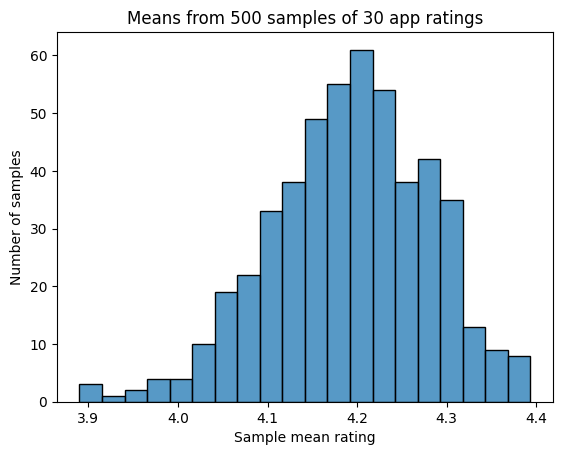

In [50]:
sns.histplot(sample_means, bins=20).set(
    title="Means from 500 samples of 30 app ratings", xlabel="Sample mean rating", ylabel="Number of samples")

Plots the distribution of the 500 sample means.

In [51]:
sample_mean = sample_means.mean()
sample_std = sample_means.std()

within_1 = sample_means.between(sample_mean - sample_std, sample_mean + sample_std).mean()
within_2 = sample_means.between(sample_mean - 2*sample_std, sample_mean + 2*sample_std).mean()
within_3 = sample_means.between(sample_mean - 3*sample_std, sample_mean + 3*sample_std).mean()

pd.Series({"Within 1 SD (compare with 68%)": within_1,
           "Within 2 SD (compare with 95%)": within_2,
           "Within 3 SD (compare with 99.7%)": within_3})

Within 1 SD (compare with 68%)      0.670
Within 2 SD (compare with 95%)      0.960
Within 3 SD (compare with 99.7%)    0.994
dtype: float64

Measures the share of sample means within one, two, and three standard deviations.

The empirical rule expects about 68%, 95%, and 99.7% within one, two, and three standard deviations for a roughly normal distribution. Compare those reference values with the proportions above.

**Observations:** Each sample has 30 ratings and we repeat 500 times. Sample means vary less than individual ratings and form a more balanced shape. The Central Limit Theorem says sample means tend to become more normal as sample size grows, under suitable sampling conditions. These app records are not a random sample of all apps.

In [52]:
sample_means_60 = []
for seed in range(500):
    sample = ratings.sample(60, random_state=seed)
    sample_means_60.append(sample.mean())
pd.Series(sample_means).std(), pd.Series(sample_means_60).std()

(np.float64(0.08952619885017528), np.float64(0.06688057491064603))

Repeats the sampling with 60 ratings and compares the variability of sample means.

The output compares spread for samples of 30 and 60. The larger sample usually has less sampling variability.

[Text(0.5, 1.0, 'Simulated bimodal example (not app data)'),
 Text(0.5, 0, 'Made-up value'),
 Text(0, 0.5, 'Count')]

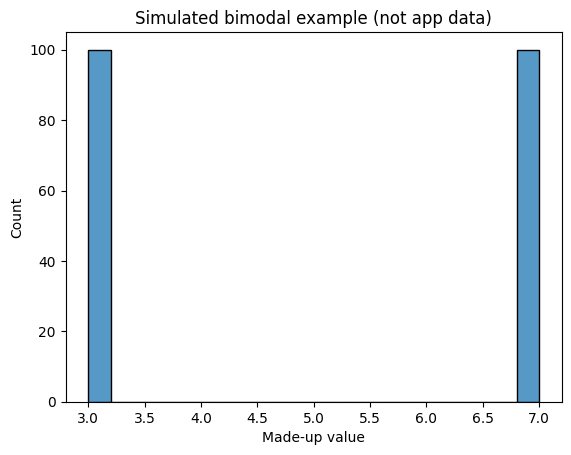

In [53]:
two_groups = pd.Series([3] * 100 + [7] * 100)
sns.histplot(two_groups, bins=20).set(
    title="Simulated bimodal example (not app data)", xlabel="Made-up value", ylabel="Count")

Plots a clearly labelled, made-up bimodal distribution for demonstration.

**Observations:** This made-up example has two groups and two peaks. It is not from Google Play data. The real rating and install plots show skew rather than this artificial two-group example.

## 10. Compare app measures
Correlation measures how two numerical values change together. Correlation does not prove that one value causes another.

In [54]:
apps[["Rating", "Reviews_num", "Installs_num", "Price_num", "Size_mb"]].cov()

,Rating,Reviews_num,Installs_num,Price_num,Size_mb
Rating,2.654505e-01,1.103803e+05,2.414057e+06,-1.784901e-01,9.678112e-01
Reviews_num,1.103803e+05,8.571782e+12,1.601024e+14,-4.514314e+05,9.374980e+06
Installs_num,2.414057e+06,1.601024e+14,7.229992e+15,-1.585318e+07,1.728662e+08
Price_num,-1.784901e-01,-4.514314e+05,-1.585318e+07,2.543930e+02,-8.709385e+00
Size_mb,9.678112e-01,9.374980e+06,1.728662e+08,-8.709385e+00,5.120577e+02


Calculates covariance between rating, reviews, installs, price, and size.

In [55]:
correlations = apps[["Rating", "Reviews_num", "Installs_num", "Price_num", "Size_mb"]].corr()
correlations

,Rating,Reviews_num,Installs_num,Price_num,Size_mb
Rating,1.000000,0.068141,0.051355,-0.021903,0.075788
Reviews_num,0.068141,1.000000,0.643122,-0.009667,0.237280
Installs_num,0.051355,0.643122,1.000000,-0.011689,0.162557
Price_num,-0.021903,-0.009667,-0.011689,1.000000,-0.022455
Size_mb,0.075788,0.237280,0.162557,-0.022455,1.000000


Calculates Pearson correlations between the selected app measures.

In [56]:
apps[["Rating", "Reviews_num", "Installs_num", "Price_num", "Size_mb"]].corr(method="spearman")

,Rating,Reviews_num,Installs_num,Price_num,Size_mb
Rating,1.000000,0.156490,0.069546,0.064280,0.047299
Reviews_num,0.156490,1.000000,0.971219,-0.170549,0.363333
Installs_num,0.069546,0.971219,1.000000,-0.242958,0.343095
Price_num,0.064280,-0.170549,-0.242958,1.000000,-0.025450
Size_mb,0.047299,0.363333,0.343095,-0.025450,1.000000


Calculates Spearman rank correlations for the selected app measures.

[Text(0.5, 1.0, 'Correlation between app measures')]

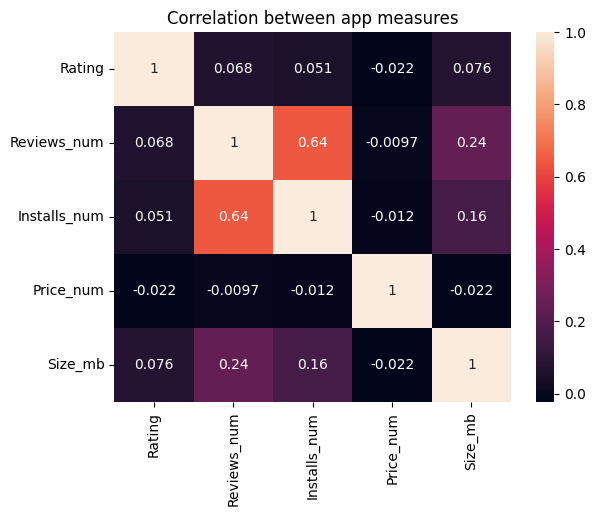

In [57]:
sns.heatmap(correlations, annot=True).set(title="Correlation between app measures")

Displays the Pearson correlation table as a heatmap.

Pearson correlation describes straight-line relationships; Spearman compares ranks. Correlations range from -1 to +1, while covariance depends on units. Read table and heatmap values to describe the strongest relationships; neither method shows cause and effect.

[Text(0.5, 1.0, 'Reviews and installs'),
 Text(0.5, 0, 'Number of reviews'),
 Text(0, 0.5, 'Number of installs')]

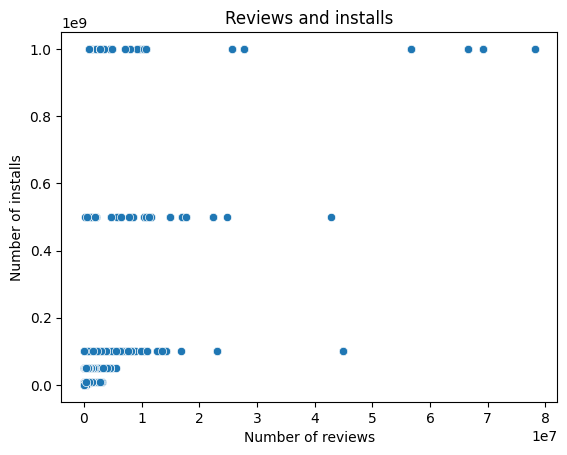

In [58]:
sns.scatterplot(data=apps, x="Reviews_num", y="Installs_num").set(
    title="Reviews and installs", xlabel="Number of reviews", ylabel="Number of installs")

Plots review counts against install counts to show their relationship.

**Observations:** Compare the direction and spread in this plot with the correlation output. Very large app counts can affect the pattern; the plot shows association only, not causation.

## 11. Find and compare outliers
An outlier is an unusually small or large value. It may still be a valid app, so inspect flagged rows before changing anything.

[Text(0.5, 1.0, 'Potential outliers in installs'),
 Text(0.5, 0, 'Number of installs'),
 Text(0, 0.5, '')]

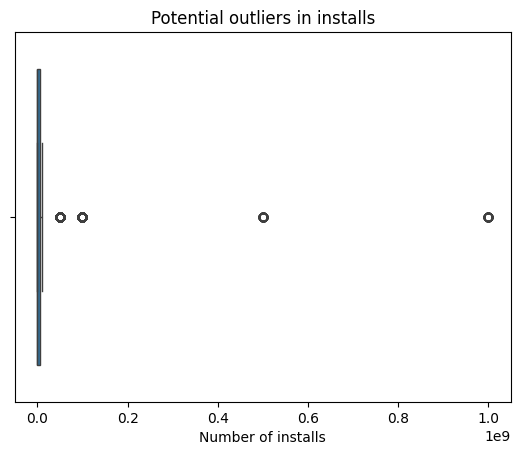

In [59]:
sns.boxplot(data=apps, x="Installs_num").set(
    title="Potential outliers in installs", xlabel="Number of installs", ylabel="")

Plots install counts on a log scale to show small and large values together.

The box plot shows the middle half of install counts and possible values beyond the whiskers. Popular apps can be valid high values.

In [60]:
q1 = apps["Installs_num"].quantile(.25)
q3 = apps["Installs_num"].quantile(.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

Removes plus signs and commas, then converts install counts to numbers.

In [61]:
iqr_outliers = apps[(apps["Installs_num"] < lower) | (apps["Installs_num"] > upper)]
len(iqr_outliers), len(iqr_outliers) / len(apps)

(828, 0.07638376383763838)

Removes plus signs and commas, then converts install counts to numbers.

In [62]:
z_scores = (apps["Installs_num"] - apps["Installs_num"].mean()) / apps["Installs_num"].std()
z_outliers = apps[z_scores.abs() > 3]
len(z_outliers), len(z_outliers) / len(apps)

(130, 0.011992619926199263)

Removes plus signs and commas, then converts install counts to numbers.

In [63]:
iqr_outliers[["App", "Category", "Installs", "Installs_num"]].head()

,App,Category,Installs,Installs_num
3,Sketch - Draw & Paint,ART_AND_DESIGN,"50,000,000+",50000000
139,Wattpad 📖 Free Books,BOOKS_AND_REFERENCE,"100,000,000+",100000000
143,Amazon Kindle,BOOKS_AND_REFERENCE,"100,000,000+",100000000
152,Google Play Books,BOOKS_AND_REFERENCE,"1,000,000,000+",1000000000
188,Indeed Job Search,BUSINESS,"50,000,000+",50000000


Displays example apps flagged as IQR outliers for inspection.

IQR uses quartiles; Z-score uses mean and standard deviation with a threshold of 3. They can flag different rows. Installs are skewed, so Z-scores need care. The table helps inspect whether flagged apps look like plausible popular apps.

In [64]:
apps_removed = apps[apps["Installs_num"].between(lower, upper)]

Removes plus signs and commas, then converts install counts to numbers.

In [65]:
apps_capped = apps.copy()
apps_capped["Installs_capped"] = apps_capped["Installs_num"].clip(lower=lower, upper=upper)

Creates a separate copy with install counts limited to the IQR boundaries.

In [66]:
apps_retained = apps.copy()

Creates a separate copy that retains every original install value.

In [67]:
apps["Installs_num"].agg(["mean", "median", "std", "min", "max"])

mean      1.546434e+07
median    1.000000e+05
std       8.502936e+07
min       0.000000e+00
max       1.000000e+09
Name: Installs_num, dtype: float64

Removes plus signs and commas, then converts install counts to numbers.

In [68]:
apps_removed["Installs_num"].agg(["mean", "median", "std", "min", "max"])

mean      1.826152e+06
median    1.000000e+05
std       3.349851e+06
min       0.000000e+00
max       1.000000e+07
Name: Installs_num, dtype: float64

Summarizes install counts after removing flagged values.

In [69]:
apps_capped["Installs_capped"].agg(["mean", "median", "std", "min", "max"])

mean      2.641346e+06
median    1.000000e+05
std       4.289582e+06
min       0.000000e+00
max       1.249850e+07
Name: Installs_capped, dtype: float64

Summarizes install counts after capping the extremes.

Removal and capping are only comparisons; original values remain unchanged. Since extreme installs may be real, retention is preferred for the main analysis. Removal can discard valid popular apps; capping reduces extreme influence but changes recorded values.

## 12. Check data quality

In [70]:
apps.isna().sum()

App                           0
Category                      0
Rating                     1474
Reviews                       0
Size                          0
Installs                      0
Type                          1
Price                         0
Content Rating                0
Genres                        0
Last Updated                  0
Current Ver                   8
Android Ver                   2
Reviews_num                   0
Installs_num                  0
Price_num                     0
Size_mb                    2011
Last_Updated                  0
Update_month                  0
Days_since_update             0
Is_paid                       0
Price_per_review            596
Category_average_rating       0
App_key                       0
dtype: int64

Counts missing values in each working-data column.

In [71]:
(apps.isna().sum() / len(apps) * 100).round(2)

App                         0.00
Category                    0.00
Rating                     13.60
Reviews                     0.00
Size                        0.00
Installs                    0.00
Type                        0.01
Price                       0.00
Content Rating              0.00
Genres                      0.00
Last Updated                0.00
Current Ver                 0.07
Android Ver                 0.02
Reviews_num                 0.00
Installs_num                0.00
Price_num                   0.00
Size_mb                    18.55
Last_Updated                0.00
Update_month                0.00
Days_since_update           0.00
Is_paid                     0.00
Price_per_review            5.50
Category_average_rating     0.00
App_key                     0.00
dtype: float64

Counts missing values in each working-data column.

In [72]:
apps["Category"].value_counts().head(10)

Category
FAMILY             1972
GAME               1144
TOOLS               843
MEDICAL             463
BUSINESS            460
PRODUCTIVITY        424
PERSONALIZATION     392
COMMUNICATION       387
SPORTS              384
LIFESTYLE           382
Name: count, dtype: int64

Shows the most common app categories as a basic consistency check.

In [73]:
((apps["Rating"] < 0) | (apps["Rating"] > 5)).sum(), (apps["Price_num"] < 0).sum()

(np.int64(0), np.int64(0))

Removes the dollar sign and converts app prices to numbers.

In [74]:
apps_raw.duplicated().sum(), apps["App"].duplicated().sum()

(np.int64(483), np.int64(1181))

Counts exact duplicate source rows and repeated app names.

In [75]:
apps["Last_Updated"].isna().sum(), apps["App_key"].isna().sum()

(np.int64(0), np.int64(0))

Converts update dates and extracts the month as a new feature.

Missing counts and percentages measure completeness. Rating should be between 0 and 5, and price should not be negative. Duplicate app names mean app name is not a unique key. We use app names to match reviews; unmatched names can occur when an app has no review records. Missing values are reported rather than silently removed.

## 13. Conclusion
The Google Play dataset supports beginner EDA with app ratings, categories, prices, install counts, update dates, and a related review table. Ratings are mostly high, while install and review counts are strongly skewed. Summarizing reviews before joining avoids multiplying app rows. Outlier methods flag unusual values but do not prove errors, so this analysis keeps valid extreme values.

**Limitations:** App names can repeat or differ between files; some app sizes are not simple MB values; some ratings and reviews are missing; and this is observational data. Correlation does not establish cause. Check each generated table and chart when presenting the project.